# Analisi spettro di Landau

Spettro acquisito con MCA (file Maestro `.Txt`, 16384 canali).
In teoria l'energia persa per ionizzazione in un piano sottile segue una **Landau**, allargata dal rumore elettronico (gaussiano): il modello sensato è quindi una **Landau ⊗ Gauss**.

Struttura del notebook:
1. lettura del file
2. spettro grezzo
3. rebinning con errori di Poisson
4. funzioni del fit (Landau parametrizzata con l'MPV, Landau ⊗ Gauss, FWHM)
5. fondo piatto e overflow
6. fit con una Landau pura
7. fit con Landau ⊗ Gauss
8. stabilità rispetto alla finestra di fit → errore sistematico
9. controllo: fit di likelihood poissoniana sui canali grezzi
10. riepilogo (e conversione in keV quando c'è la calibrazione)

In [41]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator
from scipy.optimize import curve_fit
from scipy.stats import landau, norm

try:
    from iminuit import Minuit   # serve solo per la sezione 9
except ImportError:
    Minuit = None

# Stile dei grafici: pulito e moderno
# sans-serif, solo assi sinistro e inferiore, griglia orizzontale leggera, colori sobri
INK, INK_2, GRID = "#1f1f1f", "#5f5e5a", "#e6e5e1"
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#e34948", "#008300"]  # ordine fisso

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica", "Arial", "DejaVu Sans"],
    "mathtext.fontset": "dejavusans",
    "font.size": 11,
    "text.color": INK,
    # assi
    "axes.facecolor": "white",
    "axes.edgecolor": INK_2,
    "axes.linewidth": 0.8,
    "axes.labelcolor": INK,
    "axes.labelsize": 11,
    "axes.labelpad": 6,
    "axes.titlesize": 13,
    "axes.titleweight": "semibold",
    "axes.titlelocation": "left",
    "axes.titlepad": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    # griglia solo orizzontale, dietro ai dati
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    # tick
    "xtick.direction": "out",
    "ytick.direction": "out",
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "xtick.labelcolor": INK,
    "ytick.labelcolor": INK,
    "xtick.major.size": 4,
    "ytick.major.size": 4,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.visible": False,
    "ytick.minor.visible": False,
    # linee e legenda
    "lines.linewidth": 1.5,
    "lines.markersize": 4,
    "errorbar.capsize": 0,
    "legend.frameon": False,
    "legend.fontsize": 10,
    "legend.handlelength": 1.6,
})

C_DATI = INK          # dati
C_CURVA = PALETTE[0]  # curva del fit
C_RIF = "#9a9893"     # linee di riferimento (finestra, zero, ...)

DATA_DIR = Path("data")

## 1. Lettura del file

In [42]:
def leggi_mca(path):
    """Legge un file spettro ASCII di Maestro (sezione SPECTRUM, 5 conteggi per riga).

    Ritorna (info, counts): info e' un dict con i campi dell'header,
    counts un array numpy con i conteggi per canale.
    """
    lines = Path(path).read_text().splitlines()
    info = {}
    for line in lines:
        if line.strip() == "SPECTRUM":
            break
        if ":" in line:
            key, _, val = line.partition(":")
            if val.strip():
                info[key.strip()] = val.strip()

    start = next(i for i, l in enumerate(lines) if l.strip() == "SPECTRUM") + 1
    counts = []
    for line in lines[start:]:
        if ":" not in line:
            break
        counts.extend(int(x) for x in line.split(":", 1)[1].split())
    return info, np.array(counts)


info, counts = leggi_mca(DATA_DIR / "LANDAU_seconda.Txt")
channels = np.arange(len(counts))
live_time = float(info["Live Time"])
real_time = float(info["Real Time"])

for k in ["Acquisition start date", "Acquisition start time", "Real Time", "Live Time", "Number of channels"]:
    print(f"{k:25s} {info[k]}")
print()
print(f"Conteggi totali          {counts.sum()}")
print(f"Rate medio               {counts.sum() / live_time:.3f} Hz")
print(f"Tempo morto              {100 * (1 - live_time / real_time):.3f} %")
print(f"Primo canale non vuoto   {np.nonzero(counts)[0].min()}  (soglia)")

Acquisition start date    19Nov2026
Acquisition start time    16:21:19
Real Time                 77620.558265
Live Time                 75980.198302
Number of channels        16384

Conteggi totali          62590
Rate medio               0.824 Hz
Tempo morto              2.113 %
Primo canale non vuoto   374  (soglia)


## 2. Spettro grezzo

Scala lineare e logaritmica. In log si vedono bene la coda lunga della Landau e il fondo piatto ad alti canali.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


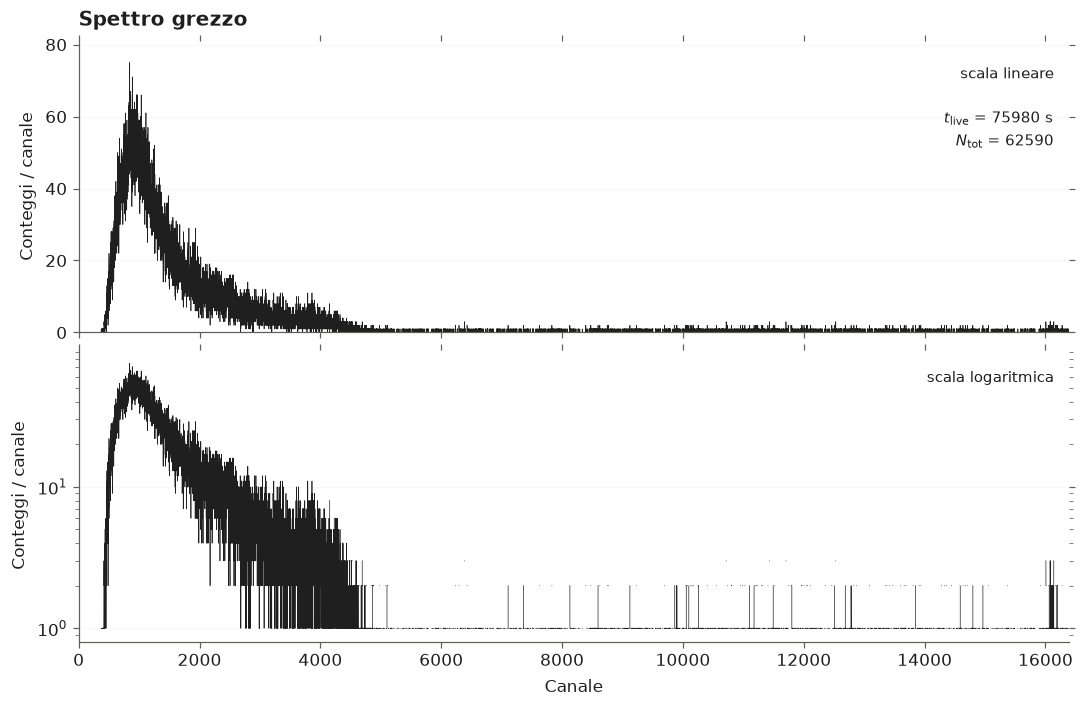

In [43]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True,
                               gridspec_kw={"hspace": 0.06})

ax1.step(channels, counts, where="mid", color=C_DATI, lw=0.45)
ax1.set_ylabel("Conteggi / canale")
ax1.set_ylim(0, counts.max() * 1.08)

ax2.step(channels, np.where(counts > 0, counts, np.nan), where="mid", color=C_DATI, lw=0.45)
ax2.set_yscale("log")
ax2.set_xlabel("Canale")
ax2.set_ylabel("Conteggi / canale")

for ax in (ax1, ax2):
    ax.set_xlim(0, len(counts))

ax1.text(0.985, 0.93,
         f"scala lineare\n\n$t_\\mathrm{{live}}$ = {live_time:.0f} s\n$N_\\mathrm{{tot}}$ = {counts.sum()}",
         transform=ax1.transAxes, ha="right", va="top", fontsize=10, linespacing=1.5)
ax2.text(0.985, 0.93, "scala logaritmica", transform=ax2.transAxes, ha="right", va="top", fontsize=10)
ax1.set_title("Spettro grezzo")

fig.subplots_adjust(left=0.08, right=0.98, top=0.93, bottom=0.09)
plt.show()

## 3. Rebinning con errori di Poisson

Con pochi conteggi per canale il rumore statistico domina: sommiamo `REBIN` canali adiacenti.
L'errore su ogni bin è $\sqrt{N}$ (Poisson).

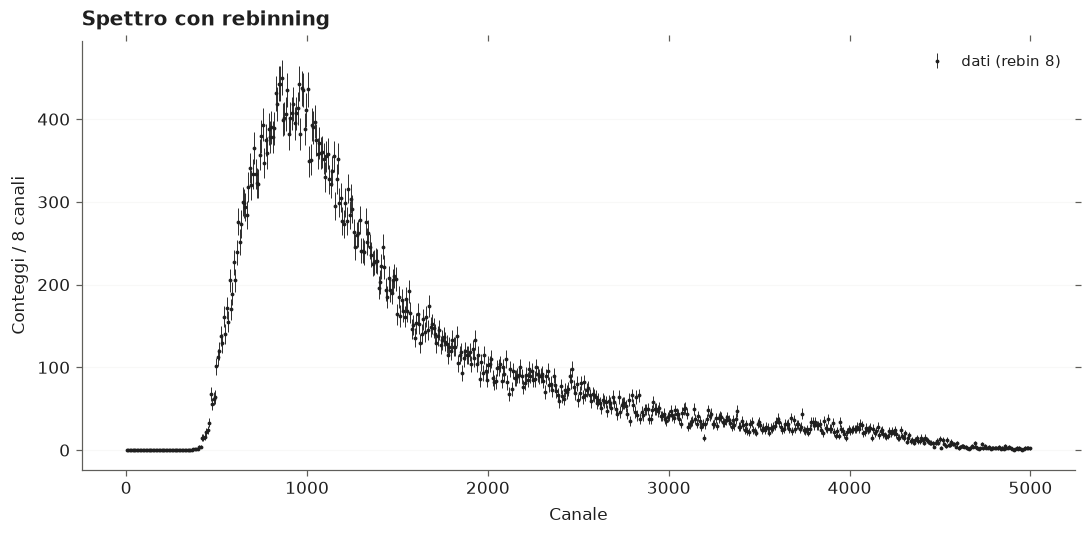

In [53]:
def rebin(counts, r):
    """Somma gruppi di r canali. Ritorna (centri, conteggi, errori, larghezza)."""
    n = len(counts) // r * r
    c = counts[:n].reshape(-1, r).sum(axis=1)
    centri = np.arange(len(c)) * r + (r - 1) / 2
    return centri, c, np.sqrt(c), r


def plot_spettro(ax, x, y, err, label=None, **kw):
    ax.errorbar(x, y, yerr=err, fmt="o", ms=2.5, mew=0, lw=0.6, color=C_DATI,
                ecolor=C_DATI, elinewidth=0.6, capsize=0, label=label, **kw)


REBIN = 8          # canali per bin: prova 4, 8, 16, 32
XMAX_ZOOM =5000 # zona del segnale

x, y, ey, w = rebin(counts, REBIN)
sel = x < XMAX_ZOOM
fig, ax = plt.subplots()
plot_spettro(ax, x[sel], y[sel], ey[sel], label=f"dati (rebin {REBIN})")
ax.set_xlabel("Canale")
ax.set_ylabel(f"Conteggi / {REBIN} canali")
ax.set_title("Spettro con rebinning")
ax.legend()
fig.tight_layout()
plt.show()

Confronto tra diversi rebinning: troppo piccolo è rumoroso, troppo grande appiattisce il picco.

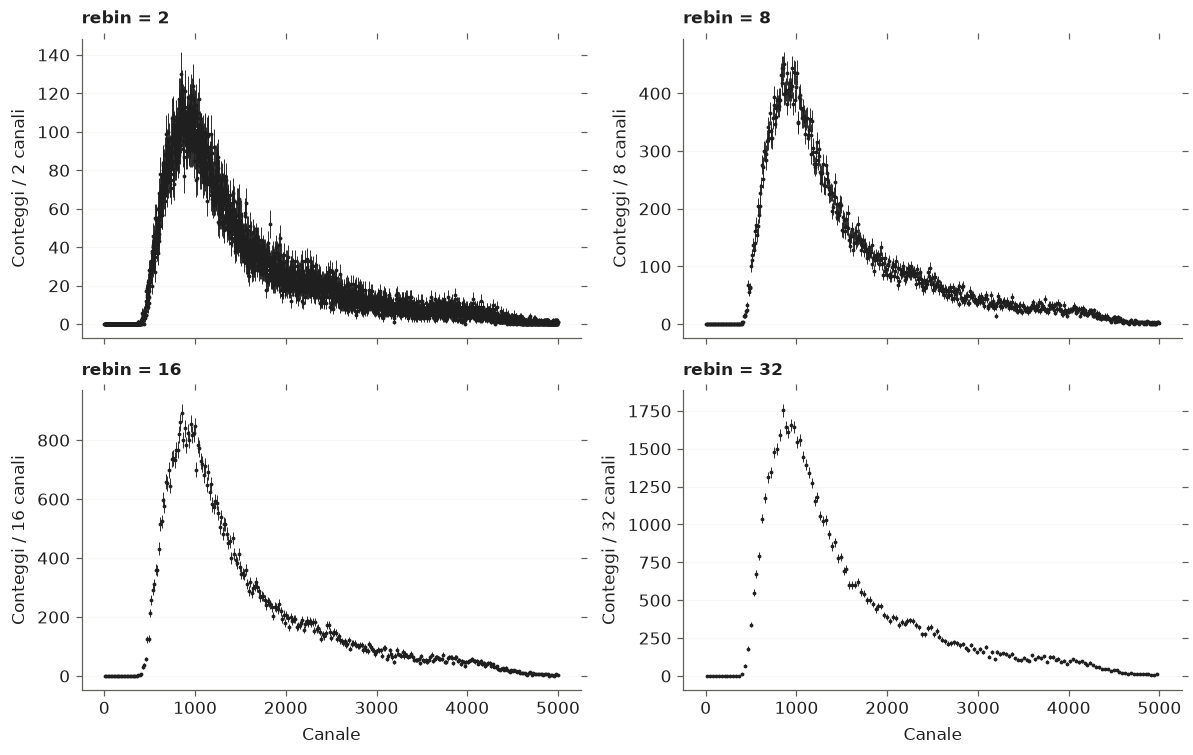

In [54]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for ax, r in zip(axes.flat, [2, 8, 16, 32]):
    xr, yr, eyr, _ = rebin(counts, r)
    s = xr < XMAX_ZOOM
    plot_spettro(ax, xr[s], yr[s], eyr[s])
    ax.set_title(f"rebin = {r}", fontsize=11)
    ax.set_ylabel(f"Conteggi / {r} canali")
for ax in axes[1]:
    ax.set_xlabel("Canale")
fig.tight_layout()
plt.show()

## 4. Funzioni del fit

**Landau parametrizzata con l'MPV.** La Landau di `scipy.stats` ha il massimo in $\mu - 0.4293\,\sigma$ e FWHM $= 2.558\,\sigma$.
Riscriviamo la funzione in modo che il parametro sia **direttamente l'MPV**: così `curve_fit` dà subito MPV ± errore, senza dover propagare la covarianza tra $\mu$ e $\sigma$.

**Landau ⊗ Gauss.** Non ha forma chiusa: la calcoliamo con una convoluzione numerica su una griglia fine.
Ha due "MPV" diversi, e conviene riportarli entrambi:
- l'MPV del **parametro Landau** = perdita di energia più probabile *senza* rumore (è quello da confrontare con la teoria);
- il **picco della curva convoluta** = dove sta il massimo che si vede nello spettro.

**Normalizzazione.** I modelli restituiscono i conteggi attesi per bin di larghezza `w` canali, quindi **N è direttamente un numero di eventi** (non più eventi × 8).

**Errori.** Se $\chi^2/\mathrm{ndf} > 1$ gli errori statistici vengono moltiplicati per $\sqrt{\chi^2/\mathrm{ndf}}$.

In [55]:
MODE_SCIPY = 0.42931   # massimo della Landau di scipy: loc - 0.42931 * scale
FWHM_SCIPY = 2.5582    # FWHM della Landau di scipy, in unita' di scale


def landau_mpv(x, mpv, sigma):
    """Densita' di Landau (normalizzata a 1) con parametro = MPV."""
    return landau.pdf(x, mpv + MODE_SCIPY * sigma, sigma)


def langaus(x, mpv, sigma, sg):
    """Landau(mpv, sigma) convoluta con una gaussiana di larghezza sg. Normalizzata a 1."""
    x = np.atleast_1d(np.asarray(x, float))
    passo = float(np.clip(sg / 5, 0.5, 2.0))           # griglia fine rispetto alla gaussiana
    m = int(np.ceil(5 * sg / passo))                    # meta' kernel (5 sigma)
    t = np.arange(x.min() - (m + 2) * passo, x.max() + (m + 3) * passo, passo)
    kernel = norm.pdf(np.arange(-m, m + 1) * passo, 0, sg) * passo
    conv = np.convolve(landau_mpv(t, mpv, sigma), kernel, mode="valid")
    return np.interp(x, t[m:len(t) - m], conv)


# Conteggi attesi per bin di larghezza w canali (+ fondo piatto B per canale, fissato nella sezione 5)
def conteggi_landau(x, N, mpv, sigma, w=1):
    return w * (N * landau_mpv(x, mpv, sigma) + B)


def conteggi_langaus(x, N, mpv, sigma, sg, w=1):
    return w * (N * langaus(x, mpv, sigma, sg) + B)


def picco_e_fwhm(f, a=0, b=8000, n=40001):
    """Posizione del massimo e FWHM (numerica) di una curva f(x)."""
    xx = np.linspace(a, b, n)
    yy = f(xx)
    i = np.argmax(yy)
    sopra = xx[yy >= yy[i] / 2]
    return xx[i], sopra[-1] - sopra[0]


def fit_binned(modello, x, y, ey, finestra, p0, bounds=(-np.inf, np.inf)):
    """Fit ai minimi quadrati nella finestra; errori scalati con sqrt(chi2/ndf) se > 1."""
    f = (x > finestra[0]) & (x < finestra[1]) & (y > 0)
    par, cov = curve_fit(modello, x[f], y[f], p0=p0, sigma=ey[f],
                         absolute_sigma=True, bounds=bounds, maxfev=20000)
    pull = (y[f] - modello(x[f], *par)) / ey[f]
    chi2, ndf = np.sum(pull ** 2), f.sum() - len(par)
    scala = np.sqrt(max(1.0, chi2 / ndf))
    return dict(par=par, err=np.sqrt(np.diag(cov)) * scala, chi2=chi2, ndf=ndf,
                scala=scala, sel=f, pull=pull, finestra=finestra)


def plot_fit(ris, modello, titolo, etichetta, testo):
    """Dati + curva del fit, con i pull (dati - fit)/errore sotto."""
    fig, (ax, axr) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True,
                                  gridspec_kw={"height_ratios": [3, 1], "hspace": 0.06})
    plot_spettro(ax, x[sel], y[sel], ey[sel], label=f"dati (rebin {REBIN})")
    xx = np.linspace(*ris["finestra"], 1500)
    ax.plot(xx, modello(xx, *ris["par"]), color=C_CURVA, lw=2, label=etichetta)
    for xv in ris["finestra"]:
        ax.axvline(xv, color=C_RIF, lw=0.8, ls="--")
    ax.text(0.97, 0.72, testo, transform=ax.transAxes, ha="right", va="top", linespacing=1.5)
    ax.set_ylabel(f"Conteggi / {REBIN} canali")
    ax.set_title(titolo)
    ax.legend()

    f = ris["sel"]
    axr.axhline(0, color=C_RIF, lw=0.8)
    axr.plot(x[f], ris["pull"], "o", ms=2.5, mew=0, color=C_DATI)
    axr.set_ylim(-5, 5)
    axr.set_ylabel("pull")
    axr.set_xlabel("Canale")
    axr.set_xlim(0, XMAX_ZOOM)
    fig.subplots_adjust(left=0.08, right=0.98, top=0.93, bottom=0.09)
    plt.show()

## 5. Fondo piatto e overflow

Sopra il bordo dello spettro resta un fondo piatto (eventi casuali, rumore, cosmici). Lo stimiamo come **conteggi medi per canale** in una zona senza segnale e lo teniamo **fisso** nei fit (`B`).

Gli ultimi canali dell'ADC raccolgono gli impulsi che superano il fondo scala (**overflow**): li contiamo e li escludiamo dal fit.

In [56]:
BKG_RANGE = (6000, 16000)   # zona senza segnale, lontana dall'overflow
N_OVERFLOW = 128            # ultimi canali considerati come overflow

zona = counts[BKG_RANGE[0]:BKG_RANGE[1]]
B = zona.mean()                              # conteggi per canale
eB = np.sqrt(zona.sum()) / len(zona)

ultimi = counts[-N_OVERFLOW:].sum()
overflow = ultimi - B * N_OVERFLOW

print(f"Fondo piatto B         = {B:.4f} +- {eB:.4f} conteggi/canale  ({B / live_time * 1e3:.4f} mHz/canale)")
print(f"Fondo atteso 0-{XMAX_ZOOM}   = {B * XMAX_ZOOM:.0f} eventi ({100 * B * XMAX_ZOOM / counts.sum():.1f}% del totale)")
print(f"Ultimi {N_OVERFLOW} canali       = {ultimi} conteggi, di cui ~{overflow:.0f} in overflow "
      f"({100 * overflow / counts.sum():.2f}% degli eventi)")

Fondo piatto B         = 0.1390 +- 0.0037 conteggi/canale  (0.0018 mHz/canale)
Fondo atteso 0-5000   = 695 eventi (1.1% del totale)
Ultimi 128 canali       = 23 conteggi, di cui ~5 in overflow (0.01% degli eventi)


## 6. Fit con una Landau pura

Stessa idea del fit originale, ma:
- la finestra parte da **550**, sopra la zona in cui agisce la soglia del discriminatore (il fronte vero parte da ~420);
- la finestra si ferma a **1800**: oltre, la coda contiene anche elettroni non al minimo di ionizzazione e una Landau sola non la descrive;
- l'MPV è un parametro, quindi ha il suo errore;
- la FWHM è calcolata dalla curva (non dipende dalla convenzione di $\sigma$).

I **pull** sotto il grafico mostrano dove il modello sbaglia: se hanno un andamento (tutti positivi in cima, tutti negativi sui fianchi...) il problema è il modello, non la statistica.

N      =      60018 +- 436   eventi
MPV    =      878.5 +- 2.6   canale
sigma  =      331.4 +- 3.6   (convenzione scipy)
FWHM   =      847.9 +- 9.3   canali
chi2/ndf = 178.8 / 153 = 1.17   (errori scalati x1.08)


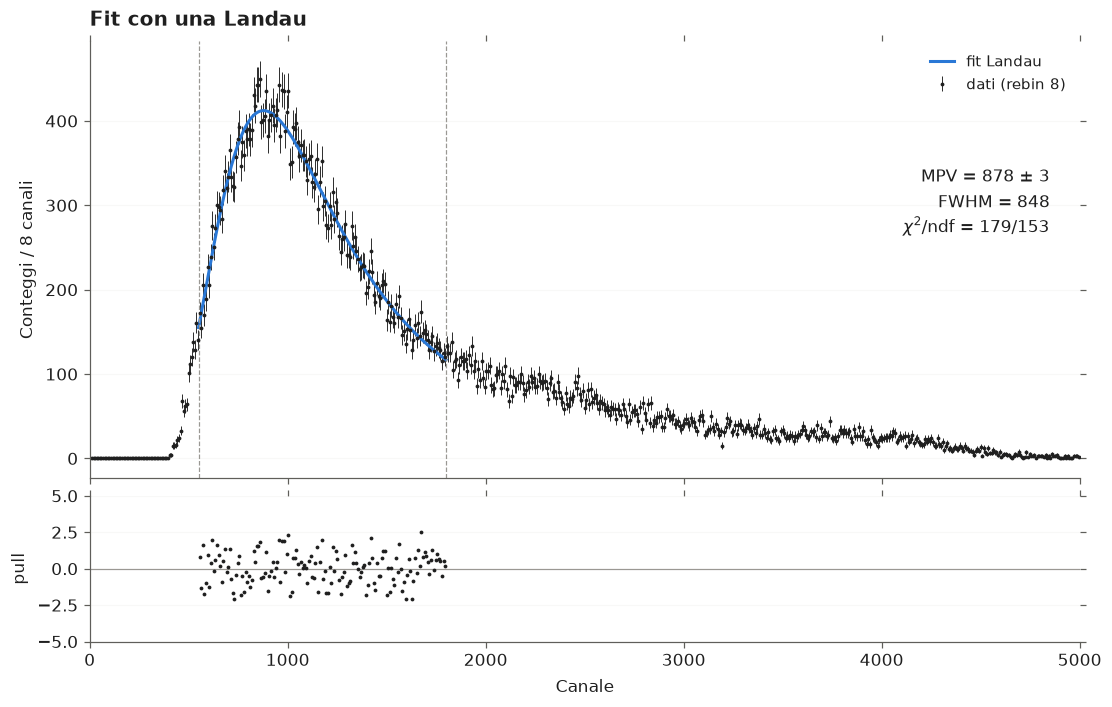

In [71]:
FIT_RANGE = (550, 1800)   # finestra di riferimento (vedi sezione 8 per le variazioni)

mod_L = lambda x, N, mpv, s: conteggi_landau(x, N, mpv, s, w=REBIN)
p0 = [counts.sum(), x[np.argmax(y)], 200]
fitL = fit_binned(mod_L, x, y, ey, FIT_RANGE, p0, bounds=([0, 0, 1], np.inf))

N_L, mpv_L, s_L = fitL["par"]
eN_L, empv_L, es_L = fitL["err"]
fwhm_L = FWHM_SCIPY * s_L

print(f"N      = {N_L:10.0f} +- {eN_L:.0f}   eventi")
print(f"MPV    = {mpv_L:10.1f} +- {empv_L:.1f}   canale")
print(f"sigma  = {s_L:10.1f} +- {es_L:.1f}   (convenzione scipy)")
print(f"FWHM   = {fwhm_L:10.1f} +- {FWHM_SCIPY * es_L:.1f}   canali")
print(f"chi2/ndf = {fitL['chi2']:.1f} / {fitL['ndf']} = {fitL['chi2'] / fitL['ndf']:.2f}"
      f"   (errori scalati x{fitL['scala']:.2f})")

plot_fit(fitL, mod_L, "Fit con una Landau", "fit Landau",
         f"MPV = {mpv_L:.0f} $\\pm$ {empv_L:.0f}\nFWHM = {fwhm_L:.0f}\n"
         f"$\\chi^2$/ndf = {fitL['chi2']:.0f}/{fitL['ndf']}")

## 7. Fit con Landau ⊗ Gauss

Parametri: N (eventi), MPV e $\sigma$ della Landau, $\sigma_G$ della gaussiana (rumore elettronico).
Partiamo dai valori del fit con la Landau pura.

$\sigma_G$ andrà confrontata con la larghezza del picco del generatore di impulsi: se sono simili, l'allargamento gaussiano è davvero il rumore elettronico.

N              =      60009 +- 440   eventi
MPV Landau     =      877.6 +- 5.1   canale  (senza rumore)
sigma Landau   =      330.2 +- 7.3
sigma Gauss    =       26.8 +- 69.2   canali  (rumore)
picco curva    =      880.0   canale  (massimo visibile)
FWHM curva     =      847.8   canali
chi2/ndf = 178.7 / 152 = 1.18   (errori scalati x1.08)


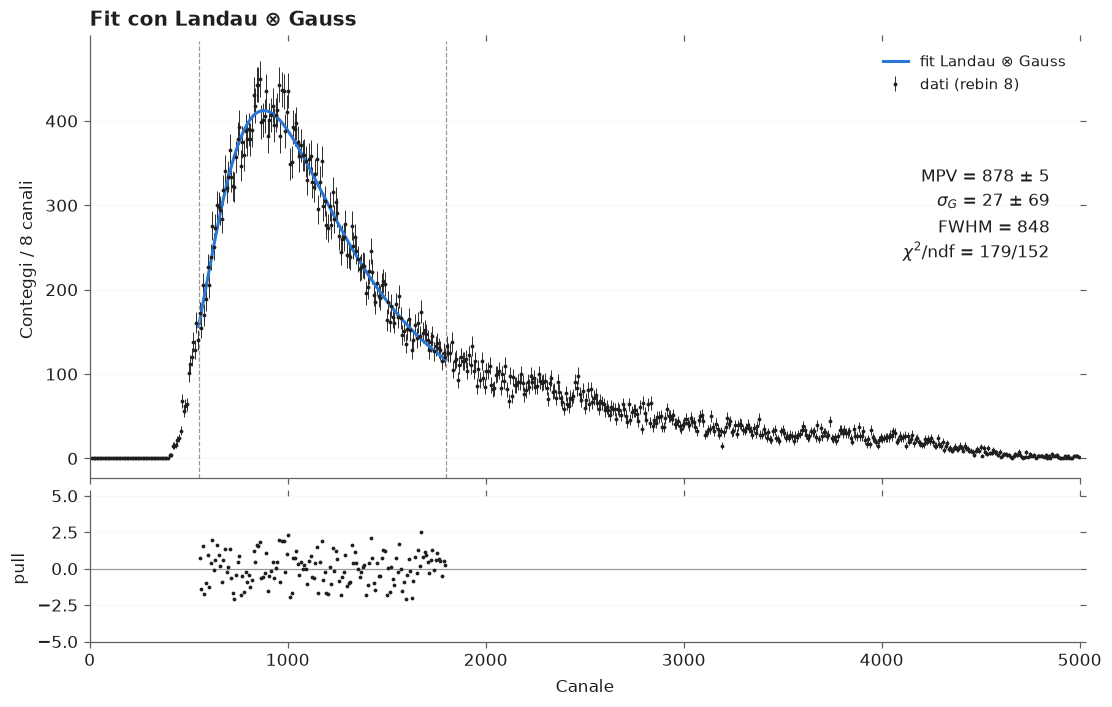

In [72]:
mod_LG = lambda x, N, mpv, s, sg: conteggi_langaus(x, N, mpv, s, sg, w=REBIN)
p0_LG = [N_L, mpv_L, 0.6 * s_L, 0.3 * s_L]
bounds_LG = ([0, 0, 1, 1], np.inf)
fitLG = fit_binned(mod_LG, x, y, ey, FIT_RANGE, p0_LG, bounds=bounds_LG)

N_G, mpv_G, s_G, sg_G = fitLG["par"]
eN_G, empv_G, es_G, esg_G = fitLG["err"]
picco_G, fwhm_G = picco_e_fwhm(lambda t: langaus(t, mpv_G, s_G, sg_G))

print(f"N              = {N_G:10.0f} +- {eN_G:.0f}   eventi")
print(f"MPV Landau     = {mpv_G:10.1f} +- {empv_G:.1f}   canale  (senza rumore)")
print(f"sigma Landau   = {s_G:10.1f} +- {es_G:.1f}")
print(f"sigma Gauss    = {sg_G:10.1f} +- {esg_G:.1f}   canali  (rumore)")
print(f"picco curva    = {picco_G:10.1f}   canale  (massimo visibile)")
print(f"FWHM curva     = {fwhm_G:10.1f}   canali")
print(f"chi2/ndf = {fitLG['chi2']:.1f} / {fitLG['ndf']} = {fitLG['chi2'] / fitLG['ndf']:.2f}"
      f"   (errori scalati x{fitLG['scala']:.2f})")

plot_fit(fitLG, mod_LG, "Fit con Landau ⊗ Gauss", "fit Landau ⊗ Gauss",
         f"MPV = {mpv_G:.0f} $\\pm$ {empv_G:.0f}\n$\\sigma_G$ = {sg_G:.0f} $\\pm$ {esg_G:.0f}\n"
         f"FWHM = {fwhm_G:.0f}\n$\\chi^2$/ndf = {fitLG['chi2']:.0f}/{fitLG['ndf']}")

## 8. Stabilità rispetto alla finestra di fit

La scelta della finestra è arbitraria, e con una coda contaminata cambia il risultato.
Rifacciamo il fit Landau ⊗ Gauss con diverse finestre: la **dispersione dell'MPV** (metà della differenza tra massimo e minimo) è l'**errore sistematico** dovuto alla finestra.

Se l'MPV si sposta molto all'aumentare di `xmax`, la coda sta "tirando" il fit: è un segno della contaminazione.

 xmin  xmax      MPV   err  sigma_G chi2/ndf
  500  1400    869.6   5.9     74.6     1.18
  500  1600    870.1   4.0     73.8     1.18
  500  1800    876.1   3.4     43.6     1.16
  500  2000    880.6   3.3      1.0     1.24
  500  2500    889.1   4.1      1.0     2.00
  550  1400    868.5   7.9     78.9     1.21
  550  1600    869.4   5.5     77.1     1.21
  550  1800    877.6   5.1     26.8     1.18
  550  2000    880.7   5.0      1.0     1.26
  550  2500    886.3   6.9      1.0     2.01
  600  1400    854.3  11.2    124.9     1.15
  600  1600    859.1   8.5    112.6     1.16
  600  1800    871.3   8.4     65.8     1.15
  600  2000    878.6   9.2      1.0     1.23
  600  2500    878.3  14.2      1.0     1.95
  650  1400    849.8  16.9    137.6     1.13
  650  1600    879.9   4.3      9.4     1.18
  650  1800    873.9  14.8     59.9     1.14
  650  2000    879.6  17.0      1.0     1.23
  650  2500    870.1  29.8      1.0     1.93

Sistematico MPV (finestra)     = 19.6 canali
Sistemati

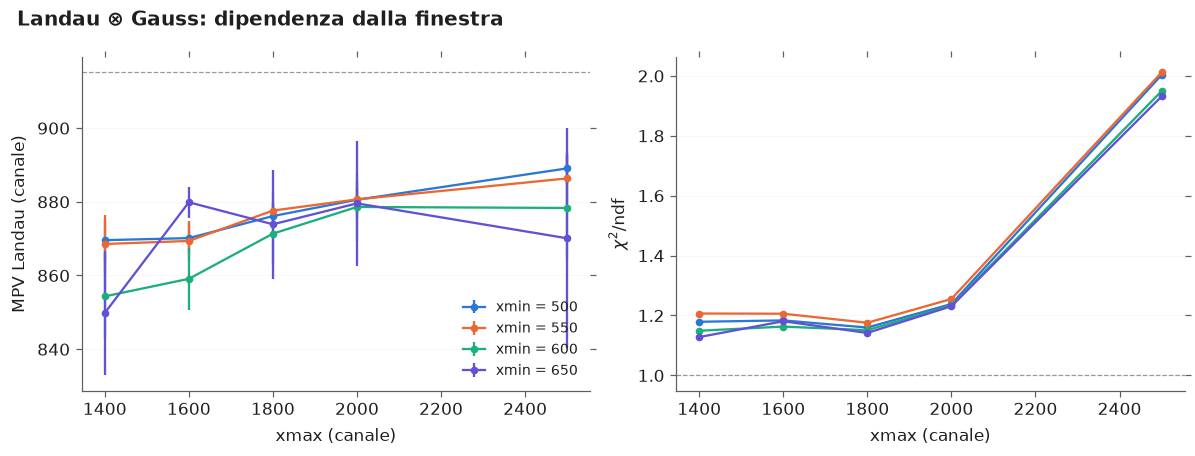

In [68]:
XMIN_LIST = [500, 550, 600, 650]
XMAX_LIST = [1400, 1600, 1800, 2000, 2500]

righe = []
for a in XMIN_LIST:
    for b in XMAX_LIST:
        try:
            r = fit_binned(mod_LG, x, y, ey, (a, b), fitLG["par"], bounds=bounds_LG)
        except RuntimeError:
            continue
        righe.append((a, b, r["par"][1], r["err"][1], r["par"][3], r["chi2"] / r["ndf"]))
righe = np.array(righe)

print(f"{'xmin':>5s} {'xmax':>5s} {'MPV':>8s} {'err':>5s} {'sigma_G':>8s} {'chi2/ndf':>8s}")
for a, b, m, e, sg, c in righe:
    print(f"{a:5.0f} {b:5.0f} {m:8.1f} {e:5.1f} {sg:8.1f} {c:8.2f}")

syst_mpv = (righe[:, 2].max() - righe[:, 2].min()) / 2
syst_sg = (righe[:, 4].max() - righe[:, 4].min()) / 2
print(f"\nSistematico MPV (finestra)     = {syst_mpv:.1f} canali")
print(f"Sistematico sigma_G (finestra) = {syst_sg:.1f} canali")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
for a in XMIN_LIST:
    r = righe[righe[:, 0] == a]
    ax1.errorbar(r[:, 1], r[:, 2], yerr=r[:, 3], fmt="o-", ms=4, lw=1.5, label=f"xmin = {a:.0f}")
    ax2.plot(r[:, 1], r[:, 5], "o-", ms=4, lw=1.5, label=f"xmin = {a:.0f}")
ax1.axhline(mpv_G, color=C_RIF, lw=0.8, ls="--")
ax1.set_xlabel("xmax (canale)")
ax1.set_ylabel("MPV Landau (canale)")
ax2.axhline(1, color=C_RIF, lw=0.8, ls="--")
ax2.set_xlabel("xmax (canale)")
ax2.set_ylabel(r"$\chi^2$/ndf")
ax1.legend(fontsize=9)
fig.suptitle("Landau ⊗ Gauss: dipendenza dalla finestra", x=0.02, ha="left", fontsize=13, fontweight="semibold")
fig.tight_layout()
plt.show()

## 9. Controllo: fit di likelihood poissoniana sui canali grezzi

Il rebin serve perché i minimi quadrati richiedono molti conteggi per bin. La likelihood poissoniana invece funziona anche con 0, 1, 2 conteggi, quindi possiamo usare **i canali grezzi** senza rebin.

Minimizziamo la forma di Baker–Cousins
$$\chi^2_\lambda = 2\sum_i \left[\mu_i - n_i + n_i \ln\frac{n_i}{\mu_i}\right]$$
che dà gli stessi parametri della likelihood e al minimo si comporta come un $\chi^2$.

**Attenzione al confronto dei $\chi^2$:** sui canali grezzi ndf è ~8 volte più grande, quindi $\chi^2_\lambda/\mathrm{ndf}$ viene più vicino a 1 anche se il modello sbaglia nello stesso modo. Per confrontare i due fit guardate l'**eccesso** $\chi^2 - \mathrm{ndf}$ (simile nei due casi se il disaccordo è lo stesso) o il p-value, non il rapporto.

Se l'MPV coincide con quello della sezione 7 entro l'errore, il risultato **non dipende dal metodo di fit**.

In [69]:
from scipy.stats import chi2 as chi2_dist

if Minuit is None:
    print("iminuit non installato: pip install iminuit")
else:
    f_raw = (channels > FIT_RANGE[0]) & (channels < FIT_RANGE[1])
    xc, n = channels[f_raw].astype(float), counts[f_raw]

    def chi2_poisson(N, mpv, sigma, sg):
        mu = np.clip(conteggi_langaus(xc, N, mpv, sigma, sg, w=1), 1e-12, None)
        termine_log = np.where(n > 0, n * np.log(np.where(n > 0, n, 1) / mu), 0.0)
        return 2 * np.sum(mu - n + termine_log)

    m = Minuit(chi2_poisson, *fitLG["par"])
    m.errordef = Minuit.LEAST_SQUARES
    m.limits["N"] = (0, None)
    m.limits["sigma"] = (1, None)
    m.limits["sg"] = (1, None)
    m.migrad()
    m.hesse()

    ndf_raw = f_raw.sum() - 4
    print(f"MPV Landau   = {m.values['mpv']:8.1f} +- {m.errors['mpv']:.1f}   (likelihood, canali grezzi)")
    print(f"MPV Landau   = {mpv_G:8.1f} +- {empv_G:.1f}   (chi2, rebin {REBIN})")
    print(f"sigma Gauss  = {m.values['sg']:8.1f} +- {m.errors['sg']:.1f}   (likelihood)")
    print(f"sigma Gauss  = {sg_G:8.1f} +- {esg_G:.1f}   (chi2)")
    print(f"chi2_lambda/ndf = {m.fval:.1f} / {ndf_raw} = {m.fval / ndf_raw:.2f}"
          f"   eccesso = {m.fval - ndf_raw:.0f},  p-value = {chi2_dist.sf(m.fval, ndf_raw):.2g}")
    print(f"chi2/ndf (rebin) = {fitLG['chi2']:.1f} / {fitLG['ndf']}"
          f"   eccesso = {fitLG['chi2'] - fitLG['ndf']:.0f},  p-value = {chi2_dist.sf(fitLG['chi2'], fitLG['ndf']):.2g}")
    diff = m.values["mpv"] - mpv_G
    print(f"\nDifferenza MPV = {diff:.1f} canali  ({abs(diff) / np.hypot(m.errors['mpv'], empv_G):.1f} sigma)")

MPV Landau   =    916.1 +- 2.0   (likelihood, canali grezzi)
MPV Landau   =    915.1 +- 3.6   (chi2, rebin 8)
sigma Gauss  =      1.0 +- 4.1   (likelihood)
sigma Gauss  =      1.0 +- 700.6   (chi2)
chi2_lambda/ndf = 4768.5 / 3595 = 1.33   eccesso = 1174,  p-value = 1.4e-36
chi2/ndf (rebin) = 1550.3 / 446   eccesso = 1104,  p-value = 7.8e-122

Differenza MPV = 1.0 canali  (0.3 sigma)


## 10. Riepilogo

Risultato di riferimento: fit Landau ⊗ Gauss nella finestra `FIT_RANGE`, con errore statistico (già scalato) e sistematico dalla finestra.

**Calibrazione (da completare).** Con il generatore di impulsi si ottiene una retta $E = A \cdot \text{canale} + B_0$. Inserite $A$, $B_0$ e lo spessore del piano: la cella converte in keV e confronta con il valore atteso per un MIP in silicio (circa 0.28 keV/µm per spessori intorno ai 300 µm; il valore esatto dipende dallo spessore, vedi PDG).
**Attenzione:** con un offset $B_0 \neq 0$ i rapporti calcolati in canali (es. FWHM/MPV) non sono uguali a quelli in energia.

In [70]:
CAL_A = None          # keV / canale   (dal generatore di impulsi)
CAL_B0 = None         # keV            (offset)
SPESSORE_UM = None    # spessore del piano in micron

print("Landau ⊗ Gauss, finestra", FIT_RANGE)
print(f"  MPV Landau  = {mpv_G:.0f} +- {empv_G:.0f} (stat) +- {syst_mpv:.0f} (sist) canali")
print(f"  sigma_G     = {sg_G:.0f} +- {esg_G:.0f} (stat) +- {syst_sg:.0f} (sist) canali")
print(f"  picco curva = {picco_G:.0f} canali,  FWHM = {fwhm_G:.0f} canali")
print(f"  N           = {N_G:.0f} +- {eN_G:.0f} eventi nella componente Landau (su {counts.sum()} totali)")

if CAL_A is not None:
    keV = lambda c: CAL_A * c + CAL_B0
    e_mpv = CAL_A * np.hypot(empv_G, syst_mpv)
    print(f"\n  MPV         = {keV(mpv_G):.1f} +- {e_mpv:.1f} keV")
    print(f"  sigma_G     = {CAL_A * sg_G:.1f} keV  (da confrontare con il picco del pulser)")
    print(f"  FWHM        = {CAL_A * fwhm_G:.1f} keV")
    if SPESSORE_UM is not None:
        print(f"  MPV / spessore = {keV(mpv_G) / SPESSORE_UM:.3f} keV/um   (atteso ~0.28 per ~300 um)")

Landau ⊗ Gauss, finestra (400, 4000)
  MPV Landau  = 915 +- 4 (stat) +- 20 (sist) canali
  sigma_G     = 1 +- 701 (stat) +- 68 (sist) canali
  picco curva = 915 canali,  FWHM = 889 canali
  N           = 62920 +- 506 eventi nella componente Landau (su 62590 totali)
